# Header: Testing empymod to grid

Goals:
- test that grid is compatible with analytic solution

v3: do this for newly designed grids also considering that source should be at the center
NOW FOR SURVEY DESIGN 3

# Code

In [205]:
import emg3d
import empymod
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from Emg3d_extra_grid_functions_v26 import *

plt.style.use('bmh')

# Comment this out on Google Colab
#%matplotlib widget

## Functions

### Load empymod values to grid

Usually we use plot_slice to plot values, but this interpolates the output to cell centers (Ez values live on the edges).
To compare emg3d results with empymod I write a function that directly plots the results using matplotlib without interpolation.

Note: we can only use the inner domain where no cell stretching is taking place: y = [-300, 300], z = [-250, -5] & cell width is constant

In [206]:
def higher_or_lower(value1, value2):
    return (value2-value1)/np.abs(value1-value2)

In [207]:
def find_distance_1d(value1, coord_list):
    distances = []
    for value2 in coord_list:
        distances.append(np.abs(value1-value2))
    return np.argmin(distances)

To insert the empymod values into the grid we need to put the values in the right location.
Ez field values are saved on the vertical edges of the grid cells, calculated at the center of the cell
Therefore we need to calculate empymod results on the vertical edges of grid cells as well
So for each receiver the x,y coordinates are given by cell centers
And the z-coordinate is given by the cell edges

We replace values in a dummy grid in the locations inside the domain.
We make sure the values correspond to the correct cell, and then can fix domain issues later

In [208]:
normal_dict = {'X': [0, 1, 2], 'Y': [1, 0, 2], 'Z' : [1, 2, 0]}

def find_Ez_slice_corners(grid, normal = 'X', slice_loc = 0, range_x=[-300, 300], range_y=[-300, 25]):

    # We need to understand where to take the slice in x,y,z coordinates
    arg_locs = [[slice_loc, slice_loc], range_x, range_y]
    arg_to_xyz = normal_dict[normal]
    x_min, y_min, z_min = arg_locs[arg_to_xyz[0]][0], arg_locs[arg_to_xyz[1]][0], arg_locs[arg_to_xyz[2]][0]
    x_max, y_max, z_max = arg_locs[arg_to_xyz[0]][1], arg_locs[arg_to_xyz[1]][1], arg_locs[arg_to_xyz[2]][1]

    # Now we locate the indeces of the required cells in the grid, noting that we acquire the Ez field values on the vertical edges
    ix_min = find_distance_1d(x_min, grid.nodes_x)
    ix_max = find_distance_1d(x_max, grid.nodes_x)
    iy_min = find_distance_1d(y_min, grid.nodes_y)
    iy_max = find_distance_1d(y_max, grid.nodes_y)
    iz_min = find_distance_1d(z_min, grid.cell_centers_z)
    iz_max = find_distance_1d(z_max, grid.cell_centers_z)

    return [ix_min, ix_max, iy_min, iy_max, iz_min, iz_max]

In [209]:
def find_Ez_slice_locs(grid, i_corners):
    
    x_locs = []
    y_locs = []
    z_locs = []
    for ix in np.arange(i_corners[0], i_corners[1]+1):
        x_locs.append(grid.nodes_x[ix])
    for iy in np.arange(i_corners[2], i_corners[3]+1):
        y_locs.append(grid.nodes_y[iy])
    for iz in np.arange(i_corners[4], i_corners[5]+1):
        z_locs.append(grid.cell_centers_z[iz])

    return [x_locs, y_locs, z_locs]

In [210]:
normal_dict2 = {'X' : [0, 1, 2], 'Y' : [1, 0, 2], 'Z' : [2, 0, 1]}

def empymod_domain(xyz_locs, inp, normal = 'X'):
        #when normal is 'X' I want to use all the y-coordinates at once

        responses = np.zeros((len(xyz_locs[0]), len(xyz_locs[1]), len(xyz_locs[2])), dtype=complex)
        len_range_y = len(xyz_locs[normal_dict2[str(normal)][2]])

        #Two of these should use only the first index, the normal and one other
        for i in np.arange(len_range_y):
            if normal == 'X':
                receivers = [xyz_locs[0][0], xyz_locs[1], xyz_locs[2][i], 0, 90]
                responses[0,:,i] = empymod.bipole(rec = receivers, **inp)
            elif normal == 'Y':
                receivers = [xyz_locs[0], xyz_locs[1][0], xyz_locs[2][i], 0, 90]
                responses[:,0,i] = empymod.bipole(rec = receivers, **inp)
            elif normal == 'Y':
                receivers = [xyz_locs[0], xyz_locs[1][i], xyz_locs[2][0], 0, 90]
                responses[:,i,0] = empymod.bipole(rec = receivers, **inp)

        return responses

In [211]:
def empymod_to_grid(grid, inp, normal = 'X', slice_loc = 0, range_x=[-300, 300], range_y=[-300, 25]):

    #Insert 0 values into grid, we assume we are computing Ez values
    grid_values = np.zeros((grid.shape_nodes[0], grid.shape_nodes[1], grid.shape_cells[2]), dtype=complex)

    #Find corner indeces
    i_corners = find_Ez_slice_corners(grid, normal, slice_loc, range_x, range_y)
    print(i_corners)

    # Find receiver locations to compute
    xyz_locs = find_Ez_slice_locs(grid, i_corners)

    #Compute responses for the receiver locations
    responses = empymod_domain(xyz_locs, inp, normal)

    #Insert into grid
    grid_values[i_corners[0]:i_corners[1]+1, i_corners[2]:i_corners[3]+1, i_corners[4]:i_corners[5]+1] = responses

    return grid_values, i_corners, xyz_locs

## Construct survey

In [213]:
# Source
src_coords = [(0, -925, 0, 90.0, 0.0),
              (-75, -925, 0, 0.0, 0.0),
              (75, -925, 0, 0.0, 0.0),
              (0, -525, 0, 90.0, 0.0),
              (-75, -525, 0, 0.0, 0.0),
              (75, -525, 0, 0.0, 0.0)]
src = []
for src_coord in src_coords:
    src.append(emg3d.surveys.txrx_coordinates_to_dict(emg3d.TxElectricDipole, src_coord))

# Source frequency
frequency = 1

# Receiver offsets
offsets = np.arange(0, 300, 7.5)  # 300 m long receiver line

# receiver-array: x, y, z, azimuth, dip
receivers = (offsets*0, [75]*len(offsets), -offsets, 0, 90)  # z-directed, Ez response

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -50, -80, -120, -190]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 52.0, 38.0, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)


In [214]:
# define the input that stays the same for all models
inp = {
    'rec': receivers,
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
}

In [215]:
print(src_coords[0])

(0, -925, 0, 90.0, 0.0)


## Create grids & models

In [216]:
# Create fine grids and models per source
f_grids = []
f_models_base = []

for i in np.arange(len(src_coords[:3])):
    src_center = src_coords[i][:3]
    f_grids.append(emg3d.construct_mesh(
        center=src_center,                                 # Center of wanted grid
        frequency=frequency,                            # Frequency we will use the grid for
        properties=[25, 1e8],                           # Reference resistivity
        domain=([-100, 100], [-1000, 100], [-300, 25]),   # Domain in which we want precise results
        center_on_edge=True,
        min_width_limits = [5, 5, 2.5],
    ))

    # Pre-allocate an array with number of cells corresponding to our grid
    res_base = np.ones(f_grids[i].shape_cells)

    # Layered base model: Fill in layered resistivities into our grid and create model
    dd = np.r_[np.inf, depth, -np.inf]
    for j in range(len(resistivities_base)):
        res_base[:, :, (f_grids[i].cell_centers_z > dd[j+1]) & (f_grids[i].cell_centers_z <= dd[j])] = resistivities_base[j]

    f_models_base.append(emg3d.Model(f_grids[i], property_x=res_base, mapping='Resistivity'))

In [217]:
# Create fine grids and models per source

for i in np.arange(3, 3+len(src_coords[3:])):
    src_center = src_coords[i][:3]
    f_grids.append(emg3d.construct_mesh(
        center=src_center,                                 # Center of wanted grid
        frequency=frequency,                            # Frequency we will use the grid for
        properties=[25, 1e8],                           # Reference resistivity
        domain=([-100, 100], [-600, 100], [-300, 25]),   # Domain in which we want precise results
        center_on_edge=True,
        min_width_limits = [5, 5, 2.5],
    ))

    # Pre-allocate an array with number of cells corresponding to our grid
    res_base = np.ones(f_grids[i].shape_cells)

    # Layered base model: Fill in layered resistivities into our grid and create model
    dd = np.r_[np.inf, depth, -np.inf]
    for j in range(len(resistivities_base)):
        res_base[:, :, (f_grids[i].cell_centers_z > dd[j+1]) & (f_grids[i].cell_centers_z <= dd[j])] = resistivities_base[j]

    f_models_base.append(emg3d.Model(f_grids[i], property_x=res_base, mapping='Resistivity'))

In [218]:
f_grids[3]  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 3,538,944 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     96   -100,983.68    100,983.68      5.00 26,632.29    1.36
   y    192   -108,975.59    108,475.59      5.00 30,913.56    1.40
   z    192   -102,815.47    102,540.47      2.50 26,495.26    1.35

In [219]:
c_grids = []
c_models_base = []

for i in np.arange(len(src_coords[:3])):
    src_center = src_coords[i][:3]
    c_grids.append(emg3d.construct_mesh(
        center=src_center,                                 # Center of wanted grid
        frequency=frequency,                            # Frequency we will use the grid for
        properties=[25, 1e8],                           # Reference resistivity
        domain=([-105, 105], [-990, 105], [-250, 5]),   # Domain in which we want precise results
        center_on_edge=True,
        min_width_limits = [15, 15, 5],
    ))

    # Pre-allocate an array with number of cells corresponding to our grid
    res_base = np.ones(c_grids[i].shape_cells)

    # Layered base model: Fill in layered resistivities into our grid and create model
    dd = np.r_[np.inf, depth, -np.inf]
    for j in range(len(resistivities_base)):
        res_base[:, :, (c_grids[i].cell_centers_z > dd[j+1]) & (c_grids[i].cell_centers_z <= dd[j])] = resistivities_base[j]

    c_models_base.append(emg3d.Model(c_grids[i], property_x=res_base, mapping='Resistivity'))

In [220]:
for i in np.arange(3, 3+len(src_coords[3:])):
    src_center = src_coords[i][:3]
    c_grids.append(emg3d.construct_mesh(
        center=src_center,                                 # Center of wanted grid
        frequency=frequency,                            # Frequency we will use the grid for
        properties=[25, 1e8],                           # Reference resistivity
        domain=([-105, 105], [-600, 105], [-250, 5]),   # Domain in which we want precise results
        center_on_edge=True,
        min_width_limits = [15, 15, 5],
    ))

    # Pre-allocate an array with number of cells corresponding to our grid
    res_base = np.ones(c_grids[i].shape_cells)

    # Layered base model: Fill in layered resistivities into our grid and create model
    dd = np.r_[np.inf, depth, -np.inf]
    for j in range(len(resistivities_base)):
        res_base[:, :, (c_grids[i].cell_centers_z > dd[j+1]) & (c_grids[i].cell_centers_z <= dd[j])] = resistivities_base[j]

    c_models_base.append(emg3d.Model(c_grids[i], property_x=res_base, mapping='Resistivity'))

In [221]:
c_grids[3]  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 589,824 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     64   -102,353.92    102,353.92     15.00 26,438.88    1.35
   y     96   -104,544.98    142,393.66     15.00 38,343.68    1.37
   z     96   -105,145.43    156,825.85      5.00 51,925.42    1.49

## Simulation of baseline model

### Emg3d simulation

Takes +/- 17 minutes per source

In [222]:
#For the fine grid
f_emg3d_rec_lines = []
f_emg3d_fields = []
f_sfields = []

for i in np.arange(len(src_coords)):

    # Generate source field
    f_sfields.append(emg3d.fields.get_source_field(f_grids[i], source=src_coords[i], frequency=frequency))

    # Baseline model
    f_emg3d_field = emg3d.solve(f_models_base[i], f_sfields[i], verb=2)
    f_emg3d_fields.append(f_emg3d_field)

    # Get receiver line response
    f_emg3d_rec_lines.append(f_emg3d_field.get_receiver(receivers, 'linear'))

:: emg3d :: 3.1e-07; 8(46); 1:50:04; CONVERGED
:: emg3d :: 6.6e-07; 7(40); 1:46:43; CONVERGED
:: emg3d :: 7.0e-07; 7(40); 3:06:27; CONVERGED
:: emg3d :: 1.7e-03; 3(21); 0:37:18; STAGNATED (returned field is zero)
:: emg3d :: 3.2e-07; 7(40); 0:55:52; CONVERGED
:: emg3d :: 3.2e-07; 7(40); 12:21:12; CONVERGED


In [223]:
#For the coarse grid
c_emg3d_rec_lines = []
c_emg3d_fields = []
c_sfields = []

for i in np.arange(len(src_coords)):

    # Generate source field
    c_sfields.append(emg3d.fields.get_source_field(c_grids[i], source=src_coords[i], frequency=frequency))

    # Baseline model
    c_emg3d_field = emg3d.solve(c_models_base[i], c_sfields[i], verb=2)
    c_emg3d_fields.append(c_emg3d_field)

    # Get receiver line response
    c_emg3d_rec_lines.append(c_emg3d_field.get_receiver(receivers, 'linear'))

:: emg3d :: 4.8e-07; 4(22); 0:02:46; CONVERGED
:: emg3d :: 4.5e-06; 3(21); 0:02:40; CONVERGED
:: emg3d :: 4.7e-06; 3(21); 0:02:42; CONVERGED
:: emg3d :: 3.5e-06; 3(21); 0:01:55; CONVERGED
:: emg3d :: 2.8e-06; 3(21); 0:01:55; CONVERGED
:: emg3d :: 3.0e-06; 3(21); 0:01:56; CONVERGED


### Empymod simulation

In [224]:
# define the input that stays the same for all models
inp2 = {
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
    'res':resistivities_base
}

In [326]:
#For the fine grid

f_empy_rec_lines = []
f_empy_fields = []
f_i_corners = []
f_xyz_locs_list = []

for i in np.arange(len(src_coords)):
    inp2['src'] = src_coords[i]

    # Compute field
    f_empy_field, i_corners, f_xyz_locs = empymod_to_grid(f_grids[i], inp2, normal = 'X', slice_loc = 0, range_x=[-750, 750], range_y=[-500, 500])
    f_empy_fields.append(f_empy_field)
    f_i_corners.append(i_corners)
    f_xyz_locs_list.append(f_xyz_locs)

    # Get receiver line response
    f_empy_rec_lines.append(empymod.bipole(**inp2, rec = receivers))

[48, 48, 100, 289, 20, 174]
[48, 48, 100, 289, 20, 174]
[48, 48, 100, 289, 20, 174]
[48, 48, 19, 177, 20, 174]
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets <

In [327]:
#For the coarse grid

c_empy_rec_lines = []
c_empy_fields = []
c_i_corners = []
c_xyz_locs_list = []

for i in np.arange(len(src_coords)):
    inp2['src'] = src_coords[i]

    # Compute field
    c_empy_field, i_corners, c_xyz_locs = empymod_to_grid(c_grids[i], inp2, normal = 'X', slice_loc = 0, range_x=[-750, 750], range_y=[-500, 500])
    c_empy_fields.append(c_empy_field)
    c_i_corners.append(i_corners)
    c_xyz_locs_list.append(c_xyz_locs)

    # Get receiver line response
    c_empy_rec_lines.append(empymod.bipole(**inp2, rec = receivers))

[32, 32, 44, 110, 14, 81]
[32, 32, 44, 110, 14, 81]
[32, 32, 44, 110, 14, 81]
[32, 32, 20, 79, 14, 81]
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m are set to 0.001 m!
* WARNING :: Offsets < 0.001 m

In [227]:
print(len(c_empy_fields))
print(np.shape(c_empy_fields[0]))
print(np.shape(c_empy_fields[1]))
print(np.shape(c_empy_fields[2]))
print(np.shape(c_empy_fields[3]))
print(np.shape(c_empy_fields[4]))

6
(65, 129, 96)
(65, 129, 96)
(65, 129, 96)
(65, 97, 96)
(65, 97, 96)


In [228]:
print(c_grids[0].nodes_x[32])
print(c_grids[0].nodes_y[44])
print(c_grids[0].nodes_y[110])
print(c_grids[0].cell_centers_z[14])
print(c_grids[0].cell_centers_z[81])

-7.773337529215496e-12
-745.0000000000122
794.5965499777756
-549.2766117939963
459.8781671263888


### Taking the difference

For some reason, it does not work to subtract the empymod_field array and the efield3D_base.fz array in their ravelled form. Therefore, I here write a loop to take the difference element-wise and this works.

In [229]:
# Test difference for a single cell

i=0

ix = 64
iy = 40
iz =50

print('Empymod: ', f_empy_fields[i][ix, iy, iz])
print('Emg3d: ', f_emg3d_fields[i].fz[ix, iy, iz])
print('Difference: ', f_empy_fields[i][ix, iy, iz]-f_emg3d_fields[i].fz[ix, iy, iz])

print('Abs. Empymod: ', np.abs(f_empy_fields[i][ix, iy, iz]))
print('Abs. Emg3d: ', np.abs(f_emg3d_fields[i].fz[ix, iy, iz]))
print('Abs. Difference: ', np.abs(f_empy_fields[i][ix, iy, iz]-f_emg3d_fields[i].fz[ix, iy, iz]))

Empymod:  0j
Emg3d:  (1.3939978199345312e-07-8.160874278181464e-10j)
Difference:  (-1.3939978199345312e-07+8.160874278181464e-10j)
Abs. Empymod:  0.0
Abs. Emg3d:  1.3940217078120449e-07
Abs. Difference:  1.3940217078120449e-07


In [230]:
# Take difference for all cells and save in an array ready to plot

c_differences = []

for i in np.arange(len(src_coords)):
    c_difference = np.zeros_like(c_empy_fields[i])
    i_corners = c_i_corners[i]
    for ix in np.arange(i_corners[0], i_corners[1]+1):
        for iy in np.arange(i_corners[2], i_corners[3]+1):
            for iz in np.arange(i_corners[4], i_corners[5]+1):
                c_difference[ix, iy, iz] = c_emg3d_fields[i].fz[ix, iy, iz] - c_empy_fields[i][ix, iy, iz]
    c_differences.append(c_difference)

In [297]:
# Take difference for all cells and save in an array ready to plot

f_differences = []

for i in np.arange(len(src_coords)):
    f_difference = np.zeros_like(f_empy_fields[i])
    i_corners = f_i_corners[i]
    for ix in np.arange(i_corners[0], i_corners[1]+1):
        for iy in np.arange(i_corners[2], i_corners[3]+1):
            for iz in np.arange(i_corners[4], i_corners[5]+1):
                f_difference[ix, iy, iz] = f_emg3d_fields[i].fz[ix, iy, iz] - f_empy_fields[i][ix, iy, iz]
    f_differences.append(f_difference)

In [232]:
# Also calculate the percentage error of this grid
c_rel_errors = []

for i in np.arange(len(src_coords)):
    c_rel_error = np.zeros_like(c_empy_fields[i])
    i_corners = c_i_corners[i]
    for ix in np.arange(i_corners[0], i_corners[1]+1):
        for iy in np.arange(i_corners[2], i_corners[3]+1):
            for iz in np.arange(i_corners[4], i_corners[5]+1):
                c_rel_error[ix, iy, iz] = c_differences[i][ix, iy, ix]/c_empy_fields[i][ix, iy, iz]
    c_rel_errors.append(c_rel_error)

In [298]:
# Also calculate the percentage error of this grid

f_rel_errors = []

for i in np.arange(len(src_coords)):
    f_rel_error = np.zeros_like(f_empy_fields[i])
    i_corners = f_i_corners[i]
    for ix in np.arange(i_corners[0], i_corners[1]+1):
        for iy in np.arange(i_corners[2], i_corners[3]+1):
            for iz in np.arange(i_corners[4], i_corners[5]+1):
                f_rel_error[ix, iy, iz] = f_differences[i][ix, iy, ix]/f_empy_fields[i][ix, iy, iz]
    f_rel_errors.append(f_rel_error)

In [234]:
print(type(f_differences[0][0,0,0]))

<class 'numpy.complex128'>


### Plots

Text(0.5, 0.98, 'Coarse grid: Show difference between emg3d and empymod for source 5')

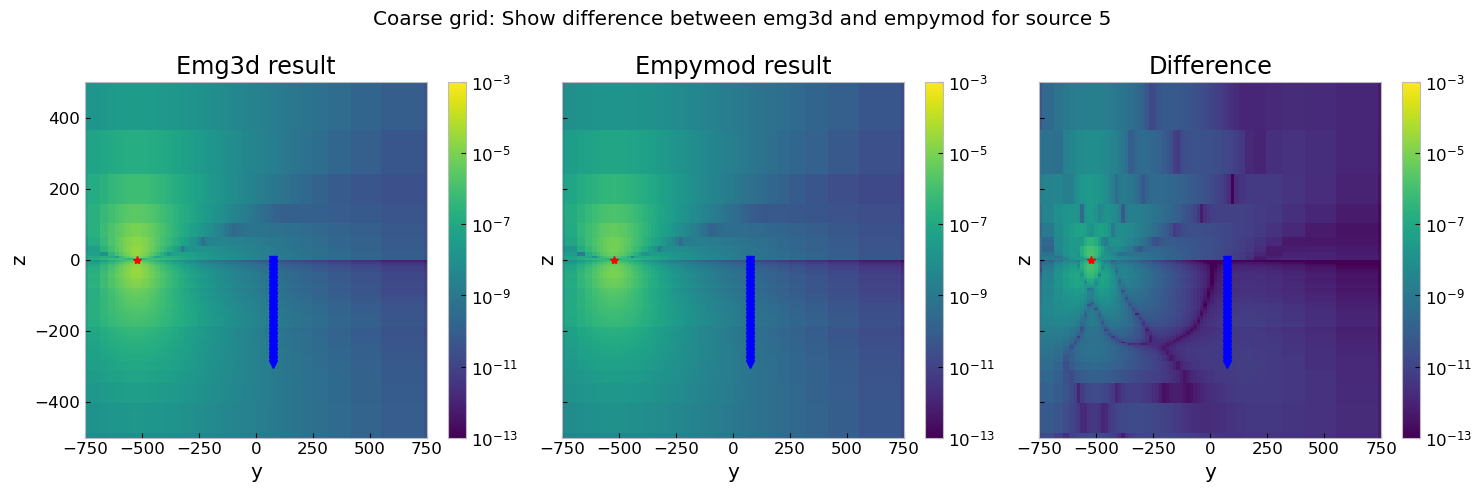

In [339]:
#Plot next to each other

j = 5

vmin = 1e-13
vmax = 1e-3

popts = {'cmap': 'viridis', 'norm': LogNorm(vmin=vmin, vmax=vmax)}
opts = {'v_type': 'Ez', 'view': 'abs', 'normal': 'X', 'range_x': [-750, 750], 'range_y': [-500, 500]}

fig, axs = plt.subplots(1, 3, figsize = (15, 5), tight_layout=True, sharex = True, sharey = True)

to_plot = [c_emg3d_fields[j].fz.ravel('F'), c_empy_fields[j].ravel('F'), c_differences[j].ravel('F')]
titles = ['Emg3d result', 'Empymod result', 'Difference']

for i in np.arange(3):
    # Plotting the fields
    f0 = c_grids[j].plot_slice(to_plot[i], ax=axs[i], pcolor_opts=popts, **opts)
    axs[i].set_title(titles[i])
    axs[i].plot(receivers[1], receivers[2], 'bv')
    axs[i].plot(src_coords[j][1], src_coords[j][2], 'r*')
    axs[i].grid(False)
    plt.colorbar(f0[0], ax=axs[i])#, fraction=.5, shrink=.8, aspect=30)

fig.suptitle('Coarse grid: Show difference between emg3d and empymod for source '+str(j))


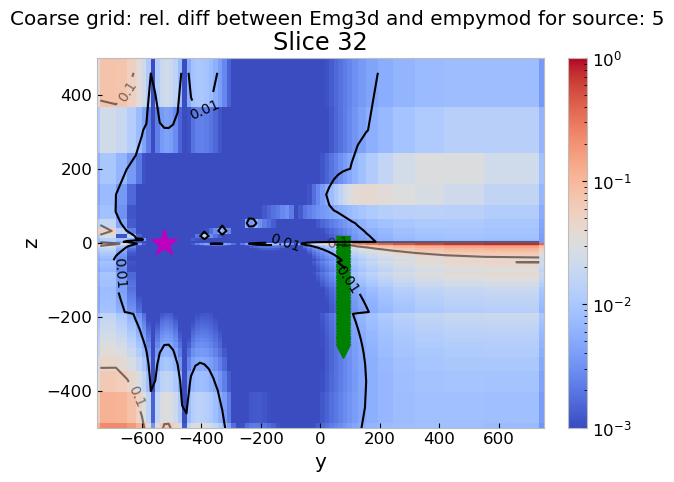

In [333]:
#Plot in the entire domain

i = 5
i_corners = c_i_corners[i]
xyz_locs = c_xyz_locs_list[i]

#Focus on the y,z plane
f0 = c_grids[i].plot_slice(
    c_rel_errors[i].ravel('F'),
    view = 'abs',
    v_type = 'Ez',
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=1e-3, vmax=1e0), 'cmap': 'coolwarm'},
    range_x=[-750, 750],
    range_y=[-500, 500],
    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Coarse grid: rel. diff between Emg3d and empymod for source: '+str(i))
axs = fig.get_children()
axs[1].plot(receivers[1], receivers[2], 'gv', markersize = 10)
axs[1].plot(src_coords[i][1], src_coords[i][2], 'm*', markersize = 20)
axs[1].grid(False)

# Add contour at relative error = 0.1
c1 = axs[1].contour(xyz_locs[1], xyz_locs[2], np.transpose(np.abs(c_rel_errors[i][i_corners[0],i_corners[2]:i_corners[3]+1, i_corners[4]:i_corners[5]+1])), levels=[0.01] ,colors=('k', 1), linewidths=1.5)
c2 = axs[1].contour(xyz_locs[1], xyz_locs[2], np.transpose(np.abs(c_rel_errors[i][i_corners[0],i_corners[2]:i_corners[3]+1, i_corners[4]:i_corners[5]+1])), levels=[0.1] ,colors=('k', 0.5), linewidths=1.5)

axs[1].clabel(c1, inline=True, fontsize=10, fmt='%.2f')
axs[1].clabel(c2, inline=True, fontsize=10, fmt='%.1f')

fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

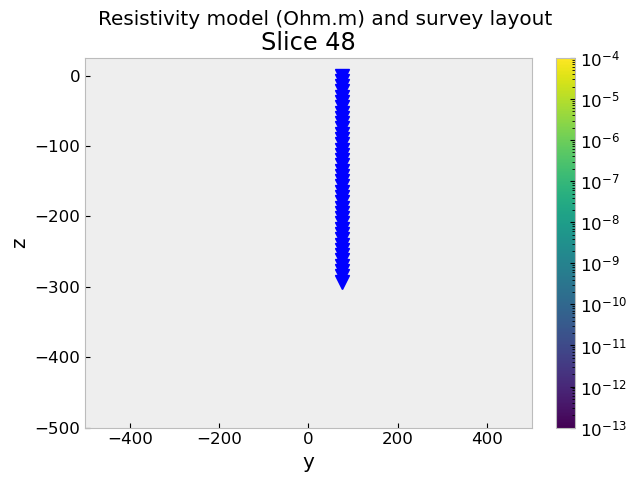

In [254]:
#Plot in the entire domain

i=0

#Focus on the y,z plane
f0 = f_grids[i].plot_slice(
    f_differences[i].ravel('F'),
    view = 'abs',
    v_type = 'Ez',
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=1e-13, vmax=1e-4)},
    range_x=[-500, 500],
    range_y=[-500, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(receivers[1], receivers[2], 'bv', markersize = 10)
axs[1].plot(src_coords[i][1], src_coords[i][2], 'r*', markersize = 20)
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

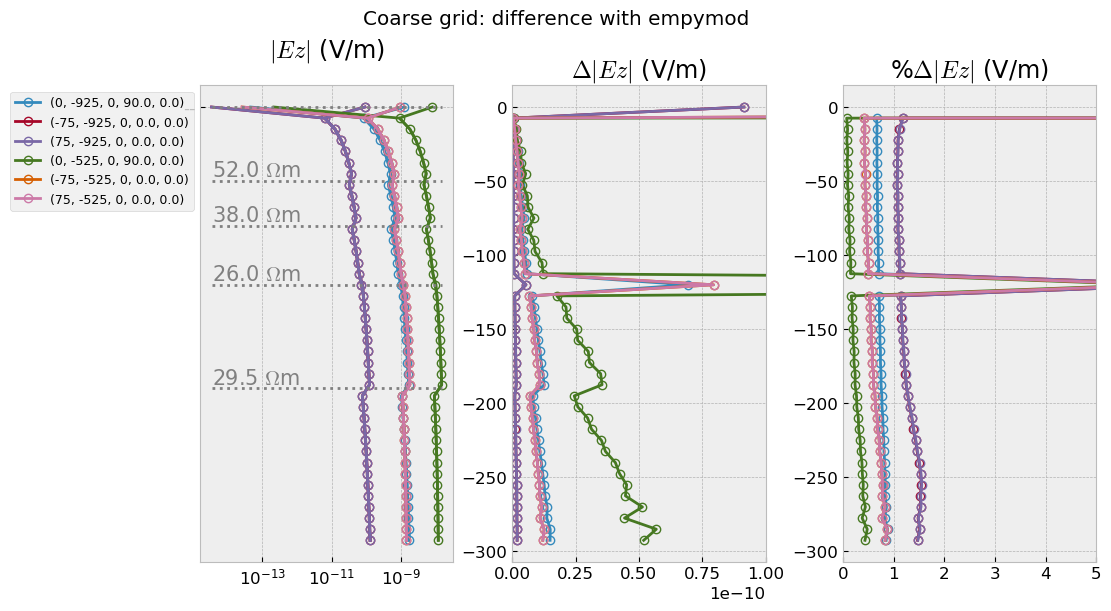

In [320]:
# Plot differences only

src_nrs = np.arange(len(src_coords))

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

fig3.suptitle("Coarse grid: difference with empymod")
plt.rcParams["font.size"] = 12

ax31.set_title('$|Ez|$ (V/m)')
ax32.set_title('$\\Delta |Ez|$ (V/m)')
ax33.set_title('%$\\Delta |Ez|$ (V/m)')

for src_nr in src_nrs:
    
    g_base = c_emg3d_rec_lines[src_nr] #emg3d
    e_base = c_empy_rec_lines[src_nr] #empymod

    ax31.plot(g_base.amp(), -offsets, 'C'+str(src_nr), marker='o', fillstyle= 'none', label = str(src_coords[src_nr]), linewidth=2)
    ax31.plot(e_base.amp(), -offsets, 'C'+str(src_nr), '--', linewidth=2) # scale your emg3d amplitues by the source length
        
    ax32.plot(np.abs(g_base-e_base), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax32.set_xlim([0, 1e-10])

    ax33.plot(100*np.abs((g_base-e_base)/e_base), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 5])

ax31.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)
ax34.set_axis_off()

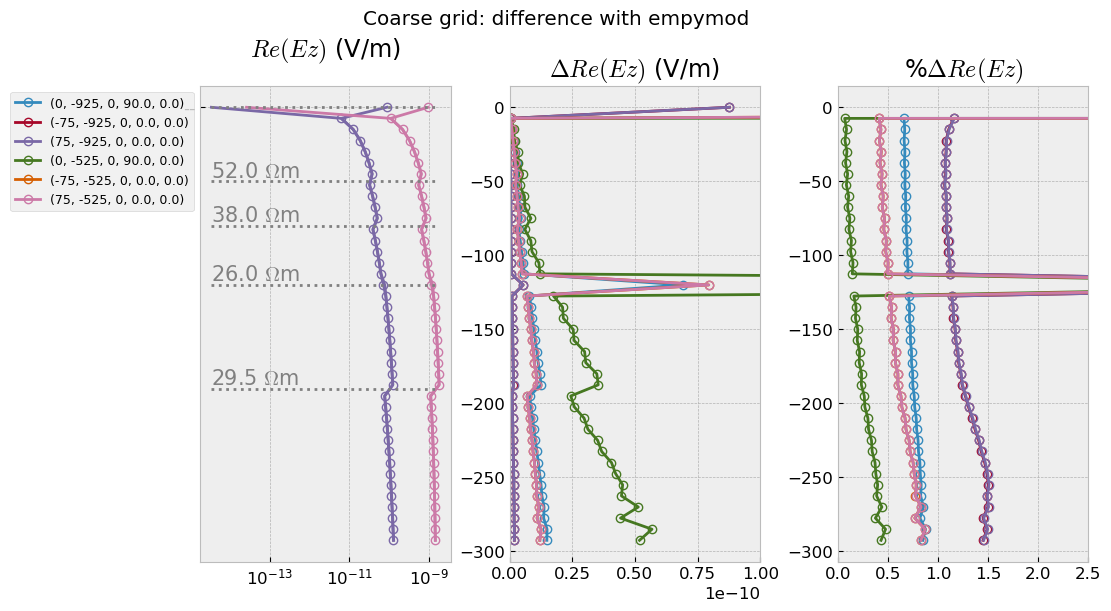

In [319]:
# Plot differences only

src_nrs = np.arange(len(src_coords))

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

fig3.suptitle("Coarse grid: difference with empymod")
plt.rcParams["font.size"] = 12

ax31.set_title('$Re(Ez)$ (V/m)')
ax32.set_title('$\\Delta Re(Ez)$ (V/m)')
ax33.set_title('%$\\Delta Re(Ez)$')

for src_nr in src_nrs:
    
    g_base = c_emg3d_rec_lines[src_nr] #emg3d
    e_base = c_empy_rec_lines[src_nr] #empymod

    ax31.plot(np.real(g_base), -offsets, 'C'+str(src_nr), marker='o', fillstyle= 'none', label = str(src_coords[src_nr]), linewidth=2)
    ax31.plot(np.real(e_base), -offsets, 'C'+str(src_nr), '--', linewidth=2) # scale your emg3d amplitues by the source length
        
    ax32.plot(np.abs(np.real(g_base)-np.real(e_base)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax32.set_xlim([0, 1e-10])

    ax33.plot(100*np.abs((np.real(g_base)-np.real(e_base))/np.real(e_base)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 2.5])

ax31.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
ax31.legend(bbox_to_anchor=(0,1), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)
ax34.set_axis_off()

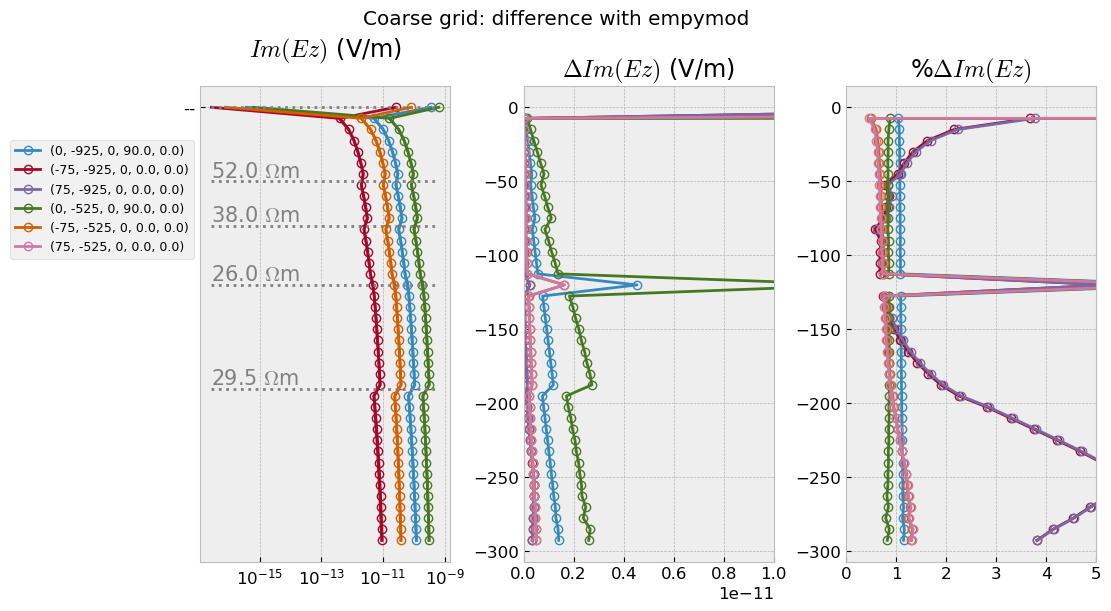

In [317]:
# Plot differences only

src_nrs = np.arange(len(src_coords))

fig3, (ax31, ax32, ax33) = plt.subplots(1, 3, figsize=(11, 6), constrained_layout=True)

fig3.suptitle("Coarse grid: difference with empymod")
plt.rcParams["font.size"] = 12

ax31.set_title('$Im(Ez)$ (V/m)')
ax32.set_title('$\\Delta Im(Ez)$ (V/m)')
ax33.set_title('%$\\Delta Im(Ez)$')

for src_nr in src_nrs:
    
    g_base = c_emg3d_rec_lines[src_nr] #emg3d
    e_base = c_empy_rec_lines[src_nr] #empymod

    ax31.plot(np.imag(g_base), -offsets, 'C'+str(src_nr), marker='o', fillstyle= 'none', label = str(src_coords[src_nr]), linewidth=2)
    ax31.plot(np.imag(e_base), -offsets, 'C'+str(src_nr), '--', linewidth=2) # scale your emg3d amplitues by the source length
        
    ax32.plot(np.abs(np.imag(g_base)-np.imag(e_base)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax32.set_xlim([0, 1e-11])

    ax33.plot(100*np.abs((np.imag(g_base)-np.imag(e_base))/np.imag(e_base)), -offsets, 'C'+str(src_nr), marker='o', fillstyle='none', linewidth=2)
    ax33.set_xlim([0, 5])

ax31.set_xscale('log')
#ax31.set_xlim([1e-7, 1e-6])
ax31.legend(bbox_to_anchor=(0,0.9), fontsize=9)
ax31.grid(visible=True, which='both')

ax34 = ax31.twiny()
ax34.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(1,len(depth)):
    ax34.text(0, depth[i]+3, str(resistivities_base[i])+' $\\Omega$m', color='gray', fontsize=15)
ax34.set_axis_off()